# 1. Import libraries

What they do:
- NumPy: handles numerical calculations.
- Pandas: organizes data into tables.
- Matplotlib: creates graphs.
- Scikit-learn: provides our dataset and helps split and scale the data.
- TensorFlow/Keras: builds and trains our neural network.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


# 2. load dataset

We'll load our dataset and the following shows what it has:

- X contains 30 features about each tumor, such as radius, texture, and smoothness.
- y contains the actual answers, Malignant or Benign.
- There are 569 samples in this dataset.
- This is a supervised learning problem because we train using data with known answers.

In [2]:
data = load_breast_cancer()

X = data.data

y = data.target

print("Shape of input data:", X.shape)
print("Shape of output data:", y.shape)
print("Feature names:", data.feature_names)
print("Target names:", data.target_names)

Shape of input data: (569, 30)
Shape of output data: (569,)
Feature names: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Target names: ['malignant' 'benign']


# 3. data split (train / test)

- splitting into 80 20 and 75 25 to find out how different splits affect the results. 

- test set is unseen data, train set is used to train the model.

- random_state=42: makes the split reproducible. Can be any int number, but using the same number ensures the same split every time you run the code.

- stratify=y, keeps the proportion of both classes approximately equal in training and testing sets. With stratify=y:
    - The model sees both tumor types in fair proportions while training.
    - The test set contains both tumor types in proportions similar to the real dataset.
    - Performance metrics such as accuracy, precision, recall, and F1-score are more reliable.

In [3]:
# 80% training and 20% testing
X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 75% training and 25% testing
X_train_75, X_test_75, y_train_75, y_test_75 = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("80:20 Split")
print("Training samples:", len(X_train_80))
print("Testing samples:", len(X_test_80))

print("\n75:25 Split")
print("Training samples:", len(X_train_75))
print("Testing samples:", len(X_test_75))


80:20 Split
Training samples: 455
Testing samples: 114

75:25 Split
Training samples: 426
Testing samples: 143


# 4. Normalize
features can have different scales. For example, tumor area can be much larger than smoothness. We normalize them so the neural network can learn more effectively.

In [4]:
scaler_80 = StandardScaler()
X_train_80 = scaler_80.fit_transform(X_train_80)
X_test_80 = scaler_80.transform(X_test_80)

scaler_75 = StandardScaler()
X_train_75 = scaler_75.fit_transform(X_train_75)
X_test_75 = scaler_75.transform(X_test_75)

print("Data normalization completed!")

Data normalization completed!


## why
Remember this for your viva
Why do we normalize? To bring features with different scales to a similar range, helping the neural network train faster and more effectively.

Why fit_transform() for training but only transform() for testing? To avoid data leakage. We calculate normalization values using only training data and apply the same values to testing data.

Me: that means we bring the values to a common standard so that the model only needs to learn that one standard instead of 2 standards for 2 different things

Yes, exactly! You've understood the main idea.

We bring all features to a common scale so that the model can learn their patterns more easily instead of struggling with different ranges of values.

One small correction: it's not exactly learning two different standards, but rather, preventing features with larger numerical values from dominating features with smaller values.

# 5: Build neural network
forward propagation and backward propagation starts here

In [5]:
model = Sequential([
    Dense(16, activation='relu', input_shape=(30,)),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.summary()


/Users/milinda/ghq/github.com/legion2004/breast-cancer-prediction/.venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

why in 1st layer, we used dense, then used  16 neurons then used relu then input_shape = 30,
wait i got the 30 part because the tumor features are 30, i mean there are 30 classes of data i believe and the tumor type is only 3. 

then we did dense again, why though and rest i got it that we are diong to learn more complex patters using the help of the previous outputs of the 16 neurons. Also why relu here again

why using sigmoid at the output layer, is it precisely because the output will be of 2 classes only, so is that the reason, explain concisely
You're almost there! Let's clear up the confusion.

1. Why input_shape=(30,)?
There are 30 features (characteristics) of each tumor, NOT 30 classes.

For example: radius, texture, perimeter, area, smoothness, etc.

There are only 2 classes: Malignant and Benign.

2. Why Dense(16)?
Dense means a fully connected layer. We choose 16 neurons because we want the first hidden layer to have 16 neurons that learn patterns from the 30 input features.

30 inputs → 16 neurons

3. Why Dense again?
Because we want another hidden layer to process the patterns learned by the first layer and learn more complex patterns.

16 neurons → 8 neurons

4. Why ReLU in both hidden layers?
Because both hidden layers need to learn patterns. ReLU introduces non-linearity, allowing the network to learn complex relationships instead of just simple linear ones.

We use ReLU in both because it is simple and works well for hidden layers.

5. Why Sigmoid in the output layer?
Yes, precisely because we have 2 classes!

Sigmoid gives a probability between 0 and 1.

Output < 0.5 → Class 0 (Malignant)

Output ≥ 0.5 → Class 1 (Benign)

Remember for your viva: ReLU is commonly used in hidden layers to learn complex patterns, while Sigmoid is used in the output layer for binary classification.

why dense, isn't there any other way to do it

and why the number 16 neurons only, why not 30
1. Why Dense? Is there any alternative?
Yes! There are different types of layers in neural networks, such as:

Dense — fully connected layer (used for general data like ours)

Conv2D — used for image processing

LSTM — used for sequential data, such as text and time series

SimpleRNN — used for sequential data

We use Dense because our dataset contains 30 numerical features about tumors, not images or sequences. Dense layers are a simple and suitable choice for this type of data.

2. Why 16 neurons? Why not 30?
Actually, we can use 30 neurons too! There is no fixed rule that the number of neurons must be 16.

We choose 16 as a hyperparameter (a value we decide before training).

2 May be too simple to learn patterns

16 Moderate complexity, a reasonable starting point

30 More learning capacity, but potentially more overfitting

128 Very high capacity, may memorize training data

So why 16? We are starting with a reasonably sized network that is easy to train and less likely to overfit than a very large one.

And later, when we demonstrate hyperparameter tuning, we can change 16 to 30, 64, or 128 and observe how the results change.

That's actually the perfect practical demonstration of why the number of neurons matters!

In [6]:

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train_80,
    y_train_80,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.6346 - loss: 0.6734 - val_accuracy: 0.6593 - val_loss: 0.6294
Epoch 2/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7088 - loss: 0.5556 - val_accuracy: 0.7582 - val_loss: 0.5496
Epoch 3/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7912 - loss: 0.4852 - val_accuracy: 0.8132 - val_loss: 0.4980
Epoch 4/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8462 - loss: 0.4340 - val_accuracy: 0.8681 - val_loss: 0.4491
Epoch 5/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8956 - loss: 0.3864 - val_accuracy: 0.9011 - val_loss: 0.3972
Epoch 6/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9093 - loss: 0.3377 - val_accuracy: 0.9231 - val_loss: 0.3463
Epoch 7/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9231 - loss: 0.2931 - val_accuracy: 0.9231 - val_loss: 0.3058
Epoch 8/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9341 - loss: 0.2584 - val_accuracy: 0.9341 - val_loss

In [7]:

test_loss, test_accuracy = model.evaluate(
    X_test_80, y_test_80, verbose=0
)

print("Test Accuracy:", test_accuracy * 100, "%")
print("Test Loss:", test_loss)


Test Accuracy: 96.49122953414917 %
Test Loss: 0.1037243977189064


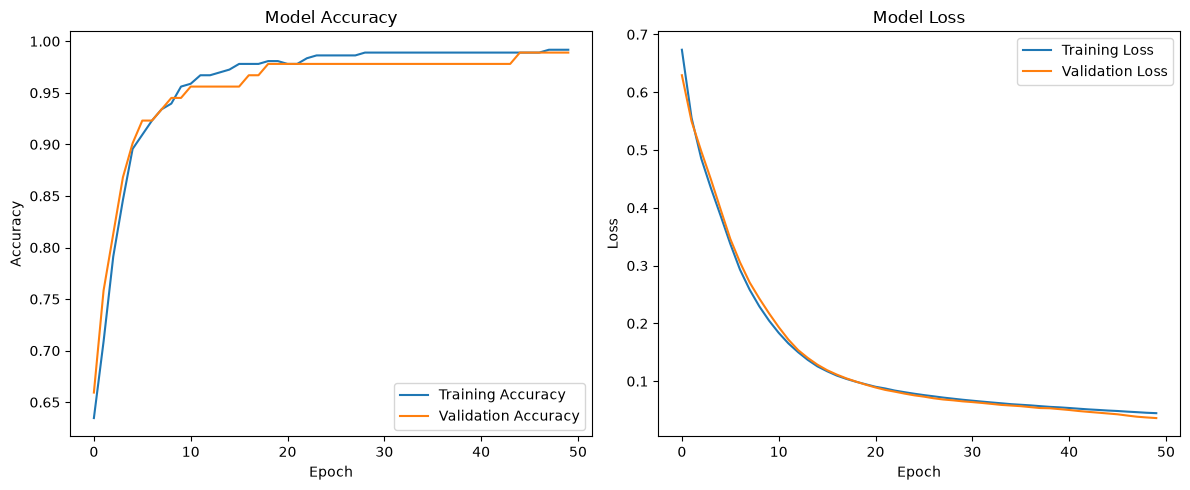

In [8]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [9]:

from tensorflow.keras.layers import Dropout
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score

# Function to create a neural network
def create_model(hidden_layers=[16, 8], regularization=None,
                dropout_rate=0, learning_rate=0.001):

    model = Sequential()

    for i, neurons in enumerate(hidden_layers):

        if i == 0:
            model.add(Dense(
                neurons,
                activation='relu',
                input_shape=(30,),
                kernel_regularizer=regularization
            ))
        else:
            model.add(Dense(
                neurons,
                activation='relu',
                kernel_regularizer=regularization
            ))

        if dropout_rate > 0:
            model.add(Dropout(dropout_rate))

    model.add(Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


In [10]:

# Model trained using 80:20 split
model_80 = create_model()

history_80 = model_80.fit(
    X_train_80, y_train_80,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

loss_80, accuracy_80 = model_80.evaluate(X_test_80, y_test_80, verbose=0)


# Model trained using 75:25 split
model_75 = create_model()

history_75 = model_75.fit(
    X_train_75, y_train_75,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

loss_75, accuracy_75 = model_75.evaluate(X_test_75, y_test_75, verbose=0)


# Display comparison
print("80:20 Test Accuracy:", round(accuracy_80 * 100, 2), "%")
print("75:25 Test Accuracy:", round(accuracy_75 * 100, 2), "%")


80:20 Test Accuracy: 95.61 %
75:25 Test Accuracy: 96.5 %


In [11]:

# Underfitting model: very few neurons
underfit_model = create_model(hidden_layers=[2])

underfit_history = underfit_model.fit(
    X_train_80, y_train_80,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# Good fitting model: moderate complexity
goodfit_model = create_model(hidden_layers=[16, 8])

goodfit_history = goodfit_model.fit(
    X_train_80, y_train_80,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# Overfitting model: very high complexity
overfit_model = create_model(hidden_layers=[128, 128, 128, 128])

overfit_history = overfit_model.fit(
    X_train_80, y_train_80,
    epochs=200,
    batch_size=8,
    validation_split=0.2,
    verbose=0
)


# Compare training and validation accuracy
print("Underfitting Model")
print("Training Accuracy:", underfit_history.history['accuracy'][-1])
print("Validation Accuracy:", underfit_history.history['val_accuracy'][-1])

print("\nGood Fit Model")
print("Training Accuracy:", goodfit_history.history['accuracy'][-1])
print("Validation Accuracy:", goodfit_history.history['val_accuracy'][-1])

print("\nOverfitting Model")
print("Training Accuracy:", overfit_history.history['accuracy'][-1])
print("Validation Accuracy:", overfit_history.history['val_accuracy'][-1])


Underfitting Model
Training Accuracy: 0.9807692170143127
Validation Accuracy: 0.9890109896659851

Good Fit Model
Training Accuracy: 0.9945054650306702
Validation Accuracy: 0.9780219793319702

Overfitting Model
Training Accuracy: 1.0
Validation Accuracy: 0.9780219793319702


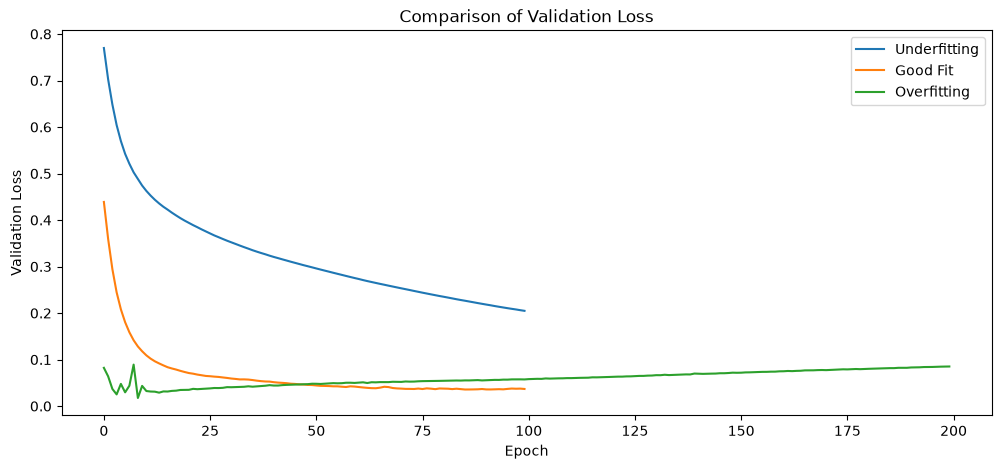

In [12]:

plt.figure(figsize=(12, 5))

plt.plot(underfit_history.history['val_loss'], label='Underfitting')
plt.plot(goodfit_history.history['val_loss'], label='Good Fit')
plt.plot(overfit_history.history['val_loss'], label='Overfitting')

plt.title('Comparison of Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.show()


In [13]:

# L1 Regularization
l1_model = create_model(
    hidden_layers=[128, 128, 128],
    regularization=l1(0.001)
)

l1_history = l1_model.fit(
    X_train_80, y_train_80,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# L2 Regularization
l2_model = create_model(
    hidden_layers=[128, 128, 128],
    regularization=l2(0.001)
)

l2_history = l2_model.fit(
    X_train_80, y_train_80,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# Compare validation loss
print("L1 Validation Loss:", l1_history.history['val_loss'][-1])
print("L2 Validation Loss:", l2_history.history['val_loss'][-1])


L1 Validation Loss: 0.07877568155527115
L2 Validation Loss: 0.05188637599349022


In [14]:

# Model without Dropout
no_dropout_model = create_model(
    hidden_layers=[128, 128, 128],
    dropout_rate=0
)

no_dropout_history = no_dropout_model.fit(
    X_train_80, y_train_80,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# Model with 30% Dropout
dropout_model = create_model(
    hidden_layers=[128, 128, 128],
    dropout_rate=0.3
)

dropout_history = dropout_model.fit(
    X_train_80, y_train_80,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


print("Without Dropout Validation Accuracy:",
      no_dropout_history.history['val_accuracy'][-1])

print("With Dropout Validation Accuracy:",
      dropout_history.history['val_accuracy'][-1])


Without Dropout Validation Accuracy: 0.9780219793319702
With Dropout Validation Accuracy: 0.9890109896659851


In [15]:

early_stop_model = create_model(
    hidden_layers=[128, 128, 128]
)

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

early_stop_history = early_stop_model.fit(
    X_train_80, y_train_80,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping],
    verbose=1
)

print("Total epochs completed:", len(early_stop_history.history['loss']))


Epoch 1/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9066 - loss: 0.3938 - val_accuracy: 0.9780 - val_loss: 0.1639
Epoch 2/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9725 - loss: 0.1192 - val_accuracy: 0.9780 - val_loss: 0.0639
Epoch 3/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9780 - loss: 0.0692 - val_accuracy: 0.9890 - val_loss: 0.0397
Epoch 4/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9863 - loss: 0.0535 - val_accuracy: 0.9890 - val_loss: 0.0316
Epoch 5/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9835 - loss: 0.0472 - val_accuracy: 1.0000 - val_loss: 0.0286
Epoch 6/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9863 - loss: 0.0368 - val_accuracy: 1.0000 - val_loss: 0.0301
Epoch 7/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9918 - loss: 0.0289 - val_accuracy: 1.0000 - val_loss: 0.0265
Epoch 8/200
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9945 - loss: 0.0220 - val_accuracy: 1.0000 - v

In [16]:

# Experiment 1: Learning rate = 0.001
model_lr1 = create_model(learning_rate=0.001)

history_lr1 = model_lr1.fit(
    X_train_80, y_train_80,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# Experiment 2: Learning rate = 0.01
model_lr2 = create_model(learning_rate=0.01)

history_lr2 = model_lr2.fit(
    X_train_80, y_train_80,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


# Experiment 3: Learning rate = 0.1
model_lr3 = create_model(learning_rate=0.1)

history_lr3 = model_lr3.fit(
    X_train_80, y_train_80,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)


print("Learning Rate 0.001:",
      history_lr1.history['val_accuracy'][-1])

print("Learning Rate 0.01:",
      history_lr2.history['val_accuracy'][-1])

print("Learning Rate 0.1:",
      history_lr3.history['val_accuracy'][-1])


Learning Rate 0.001: 0.9890109896659851
Learning Rate 0.01: 0.9890109896659851
Learning Rate 0.1: 0.9890109896659851


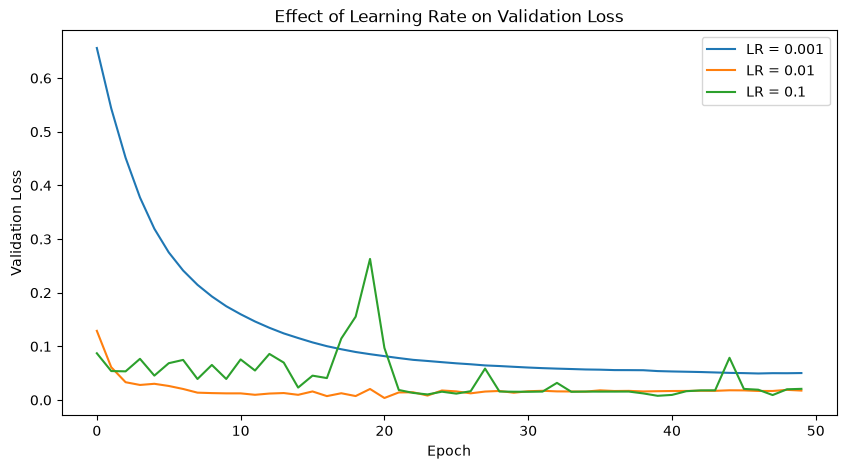

In [17]:

plt.figure(figsize=(10, 5))

plt.plot(history_lr1.history['val_loss'], label='LR = 0.001')
plt.plot(history_lr2.history['val_loss'], label='LR = 0.01')
plt.plot(history_lr3.history['val_loss'], label='LR = 0.1')

plt.title('Effect of Learning Rate on Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.show()


In [18]:

results = {
    "Normal Model": goodfit_history.history['val_accuracy'][-1],
    "L1 Regularization": l1_history.history['val_accuracy'][-1],
    "L2 Regularization": l2_history.history['val_accuracy'][-1],
    "Dropout": dropout_history.history['val_accuracy'][-1],
    "Early Stopping": early_stop_history.history['val_accuracy'][-1]
}

results_df = pd.DataFrame(
    list(results.items()),
    columns=["Technique", "Validation Accuracy"]
)

results_df["Validation Accuracy"] = (
    results_df["Validation Accuracy"] * 100
).round(2)

print(results_df)


           Technique  Validation Accuracy
0       Normal Model                 97.8
1  L1 Regularization                 98.9
2  L2 Regularization                 97.8
3            Dropout                 98.9
4     Early Stopping                100.0
